# Übung 2 - Aufgabe 1 - Klassifikation von Katzen und Hunden

In dieser Aufgabe soll der im Buch vorgestellte Datensatz verwendet werden, um Katzen und Hunde zu klassifizieren. Im Gegensatz zur vorherigen Aufgabe soll in dieser allerdings mittels fortgeschritteneren Netzen klassifiziert werden. Verwenden Sie dazu CNNs folgender Typen:

- Ein eigenes CNN angelehnt an das aus dem Buch
- Ein VGG Ihrer Wahl
- Ein ResNet Ihrer Wahl

Verwenden Sie zusätzlich ein Netz auf Basis von Vision Transformern. Vergleichen Sie die Ergebnisse. Gehen Sie auf diese Weise vor ist es sinnvoll sich für das Training eine wiederverwendbare Funktion zu schreiben.

Diese Aufgabe ist folgendermaßen aufgebaut:

1. Vornehmen nötiger Imports
2. Laden der Daten
3. Definition des eigenen CNN
4. Anlegen der neuronalen Netze
5. Training und Tests der neuronalen Netze

## 1. Nötige Imports vornehmen

Die folgende Code-Zelle importiert die notwendigen Bibliotheken, die im Folgenden benötigt werden.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import torchvision.models as models
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import numpy as np

## 2. Trainingsdaten laden

Zunächst werden die Trainingsdaten aus dem Verzeichnis geladen. Hierbei können Sie wie im Buch beschrieben vorgehen.

In [2]:
from pathlib import Path


path = Path('Data')
train_path = path / 'train'
valid_path = path / 'valid'

# Resize the images to 224x224 and convert them to tensors.
# Normalization according to the models documentation.
transform = transforms.Compose([transforms.Resize((224, 224)),
                                transforms.RandomHorizontalFlip(),
                                transforms.RandomRotation(0.2),
                                transforms.ToTensor(),
                                transforms.Normalize(mean = [0.485, 0.456, 0.406],
                                                    std = [0.229, 0.224, 0.225])])


# Hier die Daten mittels ImageFolder in Trainset und Validset einlesen
train_set = datasets.ImageFolder(train_path, transform=transform)
valid_set = datasets.ImageFolder(valid_path, transform=transform)

In [3]:
# Calculate the mean and std of the three channels of all images in train_dataset
# mean = [0.485, 0.456, 0.406]
# std = [0.229, 0.224, 0.225]

image_set = datasets.ImageFolder(train_path, transform=transforms.Compose([transforms.ToTensor()]))
image_set_mean = torch.mean(torch.stack([torch.mean(img[0], dim=(1, 2)) for img in image_set]), dim=0)
image_set_std = torch.std(torch.stack([torch.std(img[0], dim=(1, 2)) for img in image_set]), dim=0)
print("Mean: ",image_set_mean)
print("Std: ",image_set_std)

Mean:  tensor([0.4858, 0.4503, 0.4123])
Std:  tensor([0.0549, 0.0535, 0.0549])


Im Folgenden kann eines der Bilder angezeigt werden.

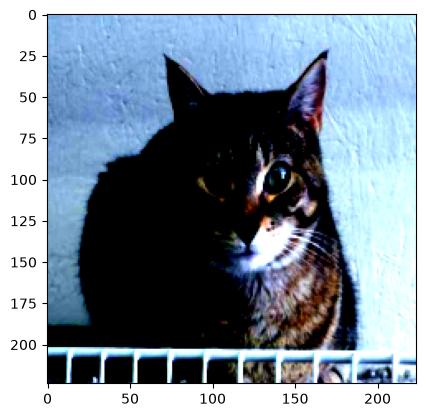

In [4]:
def imshow(inp):
    inp = inp.numpy().transpose((1, 2, 0))
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)

imshow(train_set[30][0])

Die Daten werden nun einem Data Loader übergeben, welcher eine Zufallsverteilung und eine Organisation in "batches" vornimmt.


In [5]:
batch_size = 128 if torch.xpu.is_available() or torch.cuda.is_available() else 64
num_workers = 4 if torch.xpu.is_available() or torch.cuda.is_available() else 0

print(f"Batch size: {batch_size}, Num workers: {num_workers}")

train_loader = DataLoader(train_set,shuffle=True,batch_size=batch_size,num_workers=num_workers, pin_memory=True)
valid_loader = DataLoader(valid_set,batch_size=batch_size,num_workers=num_workers, pin_memory=True)

Batch size: 128, Num workers: 4


/home/schuermanns/repos/aki-dl/.venv/lib/python3.12/site-packages/torch/xpu/__init__.py:251: UserWarning: Can't initialize Level Zero Sysman
  return _enum_zes_device_infos(visible_mask)


## 3. Definition des eigenen CNN

Nutzen Sie die vorgegebene Klasse CNN, um ein eigenes CNN zu implementieren. Aufgrund der Größe der Eingabebilder, sollte dieses mindestens 4-5 Conv2D-Schichten enthalten.

In [6]:
from torch import max_pool2d


num_classes = 2

class CNN(nn.Module):
    def __init__(self, num_classes: int):
        super().__init__()
        # Initialisieren Sie hier Ihre CNN und FC Layer.

        # input_size, da RGB in 3 Layern dargestellt wird. 
        # output_size, auf 12 gesetzt.
        # Bei 224x224 Pixeln, 3x3 Kernel, stride=1, padding=0, ergibt sich eine output_size von 222x222.
        self.layer1 = nn.Sequential(
            nn.Conv2d(3, 12, kernel_size=3, stride=1),
            nn.ReLU())


        # input_size 12, da output_size von layer1 12 ist.
        # output_size, auf 12 gesetzt.
        # Bei 222x222 Pixeln, 3x3 Kernel, stride=1, padding=0, ergibt sich eine output_size von 220x220.
        # Durch die AvgPool2d(2) wird die output_size auf 110x110 reduziert.
        self.layer2 = nn.Sequential(
            nn.Conv2d(12, 12, kernel_size=3,stride=1),
            nn.ReLU(),
            nn.AvgPool2d(2)
        )

        # input_size 12, da output_size von layer2 12 ist.
        # output_size, auf 12 gesetzt.
        # Bei 110x110 Pixeln, 3x3 Kernel, stride=1, padding=0, ergibt sich eine output_size von 108x108.
        # Durch die AvgPool2d(4) wird die output_size auf 27x27 reduziert.
        self.layer3 = nn.Sequential(
            nn.Conv2d(12, 12, kernel_size=3,stride=1),
            nn.ReLU(),
            nn.AvgPool2d(4)
        )

        # input_size 12, da output_size von layer3 12 ist.
        # output_size, auf 12 gesetzt.
        # Bei 27x27 Pixeln, 3x3 Kernel, stride=1, padding=0, ergibt sich eine output_size von 25x25.
        # Durch die AvgPool2d(5) wird die output_size auf 5x5 reduziert.
        self.layer4 = nn.Sequential(
            nn.Conv2d(12, 12, kernel_size=3,stride=1),
            nn.ReLU(),
            nn.AvgPool2d(5)
        )

        # Input ist 12*5*5, da output_size von layer4 12 ist und die AvgPool2d(5) die output_size auf 5x5 reduziert.
        # Output ist num_classes, da wir die Anzahl der Klassen als Parameter übergeben.
        self.layer5 = nn.Sequential(
            nn.Flatten(1),
            nn.Linear(12*5*5, num_classes),
        )
    

    def forward(self, x):
        # Implementieren Sie hier die Verbindung zwischen den Layern.
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.layer5(x)

        return F.log_softmax(x, dim=1)

## 4. Anlegen der neuronalen Netze

Legen Sie in der nächsten Zelle die vier Netze der vorgegebenen Typen an. Denken Sie daran die Ausgabe auf die Anzahl der vorliegenden Klassen anzupassen. Beim VGG lässt sich dies im letzten Layer der Sequenz "classifier" und beim Vision Transformer im letzten Layer der Sequenz "heads" setzen. Das ResNet können Sie wie im Kapitel 3 beschrieben anpassen.

In [11]:
def prepare_vgg(model: models.VGG, n_classes: int):
    # Code für das Setzen des letzten VGG Layers
    # Deactivate training on the pretrained features.
    for param in model.parameters(recurse=True): param.requires_grad = False

    # VGG uses a sequential module as the last layers. We want to address the last linear layer to use only
    # our n_classes instead of the pretrained 1000 ones. 
    # Reference: https://github.com/pytorch/vision/blob/main/torchvision/models/vgg.py#L98
    # An alternative would be to use models.vgg16(pretrained=True, num_classes=n_classes)
    old_classifier = model.classifier[6]
    assert isinstance(old_classifier, nn.Linear)
    model.classifier[6] = nn.Linear(old_classifier.in_features, n_classes)

    return model

def prepare_resnet(model: models.ResNet, n_classes: int):
    # Code für das Setzen des letzten ResNet Layers
    # Deactivate training on the pretrained features.
    for param in model.parameters(recurse=True): param.requires_grad = False

    # Resnet uses a single linear layer as the last layer. We want to address the last linear layer to use only
    # our n_classes instead of the pretrained 1000 ones. 
    # Reference: https://github.com/pytorch/vision/blob/main/torchvision/models/resnet.py#L166
    # An alternative would be to use models.resnet18(pretrained=True, num_classes=n_classes)
    old_classifier = model.fc
    assert isinstance(old_classifier, nn.Linear)
    model.fc = nn.Linear(old_classifier.in_features, n_classes)

    return model

def prepare_vit(model: models.VisionTransformer, n_classes: int):
    # Code für das Setzen des letzten VisionTransformer Layers
    for param in model.parameters(recurse=True): param.requires_grad = False

    # Vision transformer are using different Sequential Layers as the last layers. 
    # In both cases the last layer is named "head". Therefore retrieve the "head" layer from the sequential layer.
    # https://github.com/pytorch/vision/blob/main/torchvision/models/vision_transformer.py#L160
    old_classifier = model.heads.get_submodule("head")
    assert isinstance(old_classifier, nn.Linear)
    model.heads.set_submodule("head", nn.Linear(old_classifier.in_features, n_classes))

    return model

cnn = CNN(num_classes)
# Hier Ihre Modelle Initialisieren und vorbereiten.
vgg = prepare_vgg(models.vgg16(), num_classes)
resnet = prepare_resnet(models.resnet18(),num_classes)
vit = prepare_vit(models.vit_b_16(),num_classes)

In [12]:
# Verify that the models are prepared correctly. All pretrained features should be frozen and the last layer should have the correct number of output classes.

def trainable_parameters(model: nn.Module):
    result = []
    for name, parameter in model.named_parameters():
        if parameter.requires_grad:
            result.append(name)
    return result

print("Trainable parameters of CNN:", trainable_parameters(cnn))
print("Trainable parameters of VGG:", trainable_parameters(vgg))
print("Trainable parameters of ResNet:", trainable_parameters(resnet))
print("Trainable parameters of ViT:", trainable_parameters(vit))


Trainable parameters of CNN: ['layer1.0.weight', 'layer1.0.bias', 'layer2.0.weight', 'layer2.0.bias', 'layer3.0.weight', 'layer3.0.bias', 'layer4.0.weight', 'layer4.0.bias', 'layer5.1.weight', 'layer5.1.bias']
Trainable parameters of VGG: ['classifier.6.weight', 'classifier.6.bias']
Trainable parameters of ResNet: ['fc.weight', 'fc.bias']
Trainable parameters of ViT: ['heads.head.weight', 'heads.head.bias']


## 5. Training des Modells

Schreiben Sie in die Funktion "train_model" die Trainingslogik der neuronalen Netze. Hier können Sie ähnlich wie bei der MNIST-Aufgabe vorgehen. Die Funktion "plot_results" kann Genauigkeit und Verlust als Plot darstellen.

In [9]:
def plot_results(epochs, training_acc, testing_acc, training_loss, testing_loss):
    plt.plot(range(epochs), training_acc, label="train_acc")
    plt.plot(range(epochs), testing_acc, label="valid_acc")
    plt.legend()
    plt.xlabel("epoch")
    plt.ylabel("accuracy")
    plt.show()

    plt.plot(range(epochs), training_loss, label="train_loss")
    plt.plot(range(epochs), testing_loss, label="valid_loss")
    plt.legend()
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.show()

device = torch.device('cpu')

if torch.xpu.is_available():
    device = torch.device('xpu')

if torch.cuda.is_available():
    device = torch.device('cuda')

print("Using: ", device)


def train_model(model: nn.Module, epochs=10, learning_rate=0.001):
    # Hier Initialiserung der Verlustfunktion vornehmen
    loss_fn = nn.CrossEntropyLoss()
    # Hier Initialiserung des Optimierers vornehmen
    optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)

    training_loss = []
    testing_loss = []
    training_acc = []
    testing_acc = []

    model = model.to(device)

    with tqdm(range(epochs)) as iterator:
        for epoch in iterator:
            train_loss = 0
            train_acc = 0

            model.train()
            for images, labels in train_loader:
                images = images.to(device)
                labels = labels.to(device)

                # Hier die Ausführung des Trainings einer einzelnen Batch ergänzen
                # Bitte an die Aktualisierung von train_loss und train_acc denken!

                optimizer.zero_grad()
                
                images_pred = model(images)

                #print("Prediction:", images_pred.shape)
                #print("Labels:", labels.shape)
                #print("Labels:", labels)
#
                #print("Content Prediction:", images_pred)
                #print("Content Labels:", labels)

                loss_score = loss_fn(images_pred, labels)

                loss_score.backward()

                optimizer.step()

                train_loss += loss_score.item() * images.size(0)
                train_acc += torch.sum(images_pred.argmax(dim=1) == labels).item()


            training_acc.append(train_acc/len(train_set))
            training_loss.append(train_loss/len(train_set))

            test_loss = 0
            test_acc = 0
            with torch.no_grad():
                for images, labels in valid_loader:
                    images = images.to(device)
                    labels = labels.to(device)
                    
                    # Hier die Ausführung des Tests einer einzelnen Batch ergänzen
                    # Bitte an die Aktualisierung von test_loss und test_acc denken!
                
                    images_pred = model(images)

                    loss_score = loss_fn(images_pred, labels)

                    test_loss += loss_score.item() * images.size(0)
                    test_acc += torch.sum(images_pred.argmax(dim=1) == labels).item()

                testing_acc.append(test_acc/len(valid_set))
                testing_loss.append(test_loss/len(valid_set))

            iterator.set_postfix_str(f"train_acc: {train_acc/len(train_set):.2f} test_acc: {test_acc/len(valid_set):.2f} train_loss: {train_loss/len(train_set):.2f} test_loss: {test_loss/len(valid_set):.2f}")

    plot_results(epochs, training_acc, testing_acc, training_loss, testing_loss)


Using:  xpu


Wenn Sie Ihre Funktion "train_model" korrekt implementiert haben und Ihre Modelle definiert sind, können Sie ihre Modelle in den folgenden vier Zellen trainieren lassen. Da der Datensatz recht groß ist, würde ich ein Training auf 3-10 Epochen begrenzen. Falls Sie eine Cuda-fähige Grafikkarten besitzen, können Sie auch länger trainieren.

  0%|          | 0/40 [00:00<?, ?it/s]

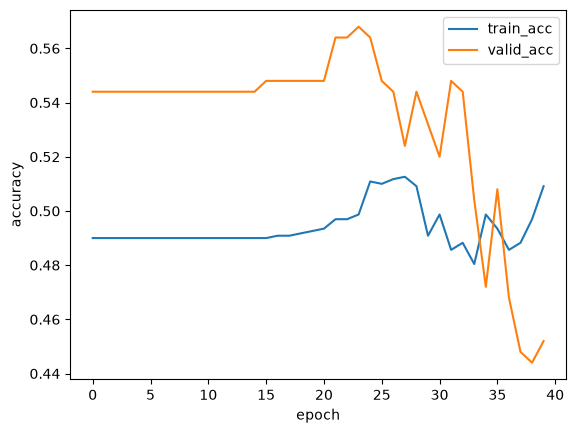

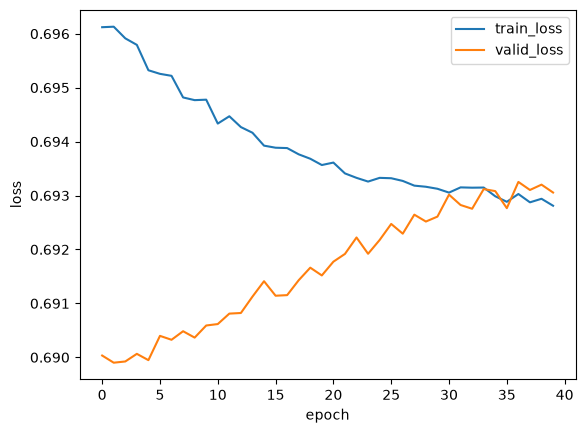

In [30]:
train_model(cnn, epochs=40)

In [ ]:
train_model(vgg, epochs=40)

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

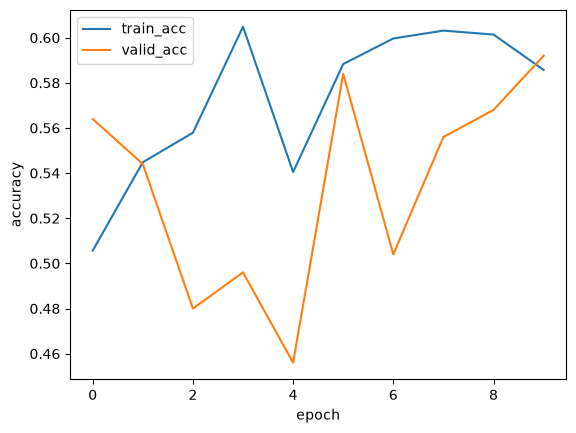

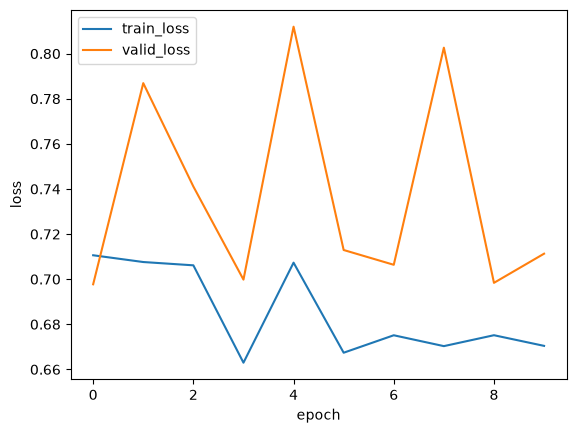

In [ ]:
train_model(resnet, epochs=40)

  0%|          | 0/40 [00:00<?, ?it/s]

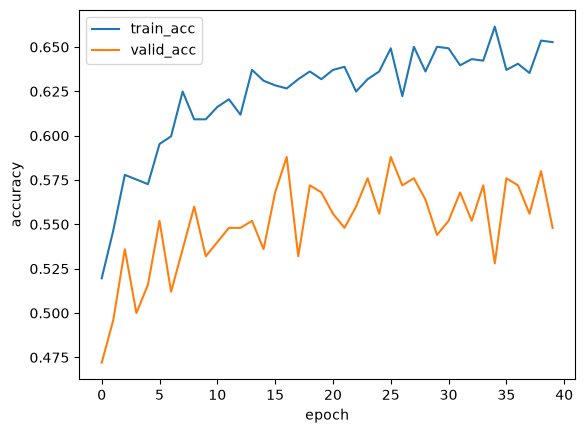

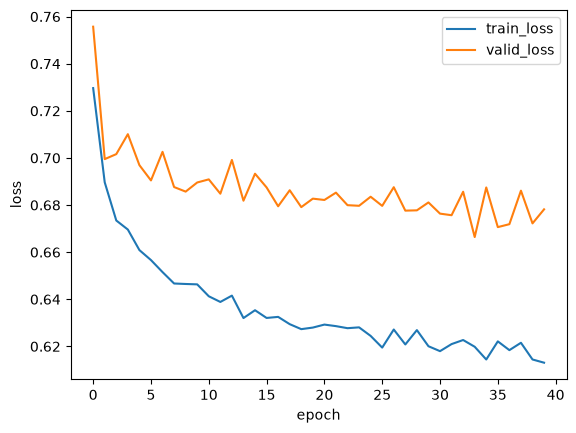

In [13]:
train_model(vit, epochs=40)